In [4]:
import pandas as pd
import numpy as np
from basin import *

In [5]:
t, r, p, s = 1.0, 0.9, 0.2, 0.0

In [6]:
epsilon = 0.2
d_values = np.linspace(0.1, 0.99, 100)

In [7]:
df_00 = {
    "d": d_values,
    "Q00": [QvaluesADvs00(t, r, p, s, epsilon, d)[0][0] for d in d_values],
    "Q01": [QvaluesADvs01(t, r, p, s, epsilon, d)[0][0] for d in d_values],
    "Q11": [QvaluesADvs11(t, r, p, s, epsilon, d)[0][0] for d in d_values],
    "QGTGT": [QvaluesGTvsGT(t, r, p, s, epsilon, d)[0][0] for d in d_values],
}
df_01 = {
    "d": d_values,
    "Q00": [QvaluesADvs00(t, r, p, s, epsilon, d)[0][1] for d in d_values],
    "Q01": [QvaluesADvs01(t, r, p, s, epsilon, d)[0][1] for d in d_values],
    "Q11": [QvaluesADvs11(t, r, p, s, epsilon, d)[0][1] for d in d_values],
    "QGTGT": [QvaluesGTvsGT(t, r, p, s, epsilon, d)[0][1] for d in d_values],
}
df_10 = {
    "d": d_values,
    "Q00": [QvaluesADvs00(t, r, p, s, epsilon, d)[1][0] for d in d_values],
    "Q01": [QvaluesADvs01(t, r, p, s, epsilon, d)[1][0] for d in d_values],
    "Q11": [QvaluesADvs11(t, r, p, s, epsilon, d)[1][0] for d in d_values],
    "QGTGT": [QvaluesGTvsGT(t, r, p, s, epsilon, d)[1][0] for d in d_values],
}
df_11 = {
    "d": d_values,
    "Q00": [QvaluesADvs00(t, r, p, s, epsilon, d)[1][1] for d in d_values],
    "Q01": [QvaluesADvs01(t, r, p, s, epsilon, d)[1][1] for d in d_values],
    "Q11": [QvaluesADvs11(t, r, p, s, epsilon, d)[1][1] for d in d_values],
    "QGTGT": [QvaluesGTvsGT(t, r, p, s, epsilon, d)[1][1] for d in d_values],
}

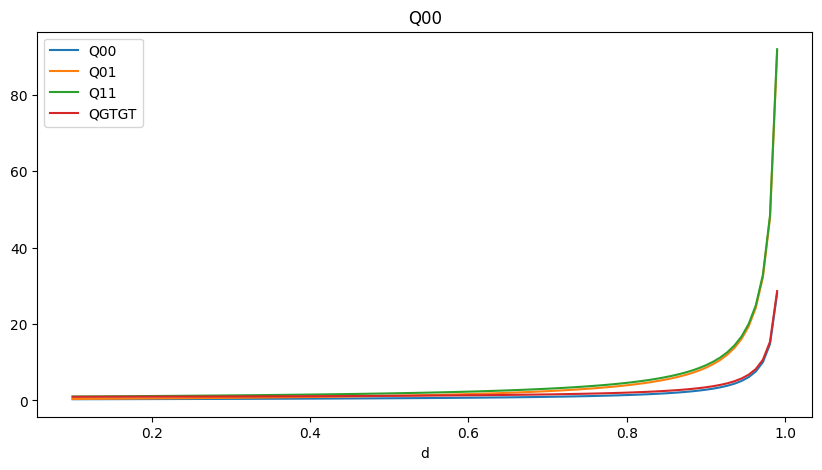

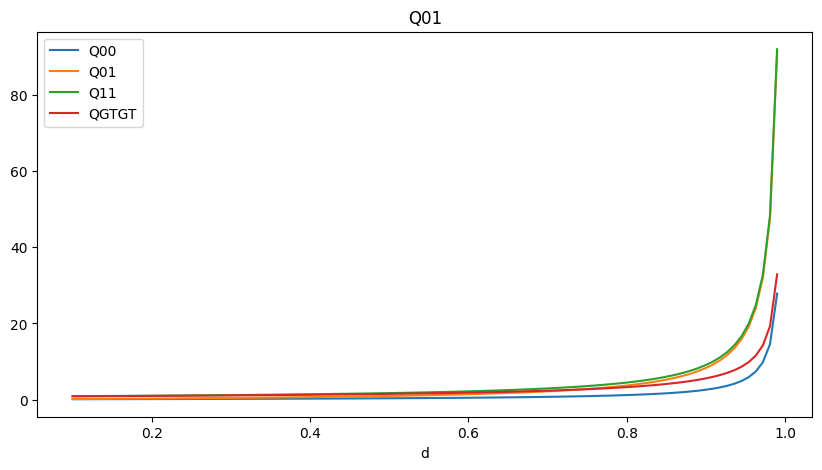

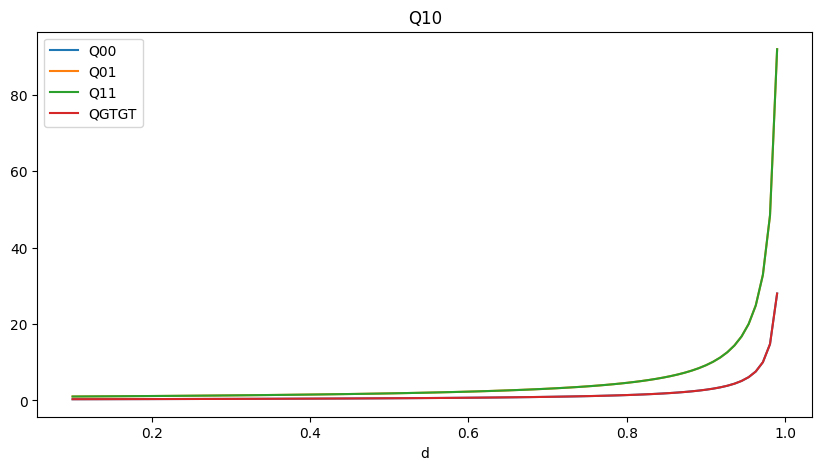

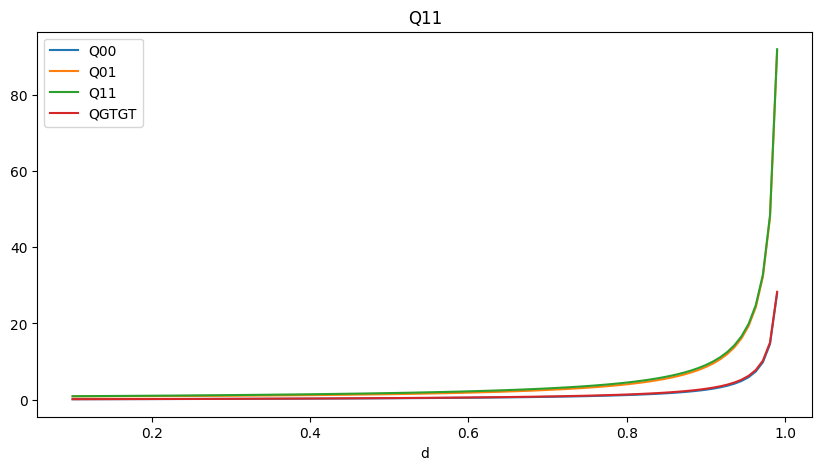

In [8]:
pd.DataFrame(df_00).set_index("d").plot(title="Q00", figsize=(10, 5))
pd.DataFrame(df_01).set_index("d").plot(title="Q01", figsize=(10, 5))
pd.DataFrame(df_10).set_index("d").plot(title="Q10", figsize=(10, 5))
pd.DataFrame(df_11).set_index("d").plot(title="Q11", figsize=(10, 5))
plt.show()

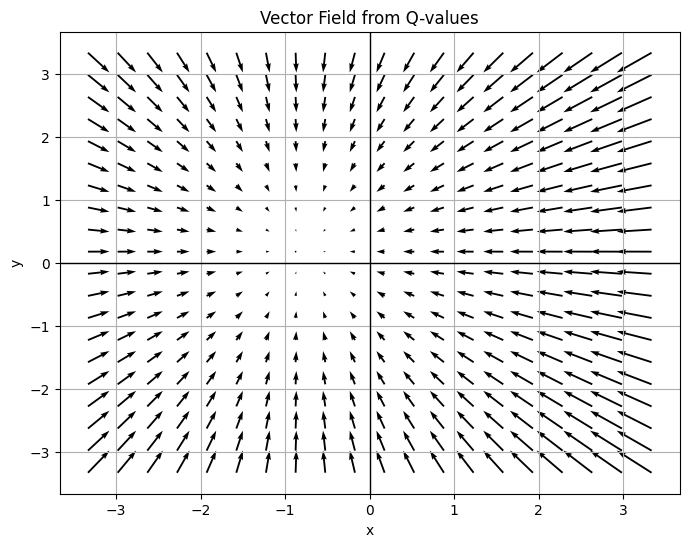

In [14]:
alpha = 0.3
d = 0.7
# Evaluate Q-values once to avoid redundant computation
Q_GT = QvaluesGTvsGT(t, r, p, s, epsilon, d)[0]
Q_AD = QvaluesADvs00(t, r, p, s, epsilon, d)[0]

# Define the vector field
def u(x, y):
    return alpha * (Q_GT[0] - Q_GT[1] - x)

def v(x, y):
    return alpha * (Q_AD[0] - Q_AD[1] - y)

# Create a grid over the desired range
x_vals = np.linspace(-1/(1 - d), 1/(1 - d), 20)
y_vals = np.linspace(-1/(1 - d), 1/(1 - d), 20)
X, Y = np.meshgrid(x_vals, y_vals)

# Evaluate the vector field
U = u(X, Y)
V = v(X, Y)

# Plot the vector field
plt.figure(figsize=(8, 6))
plt.quiver(X, Y, U, V, angles='xy', scale_units='xy', scale=3)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.5)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Vector Field from Q-values')
plt.grid(True)
plt.show()

In [46]:
# Parameters
t = 1
s = 0
r = 0.8
p = 0.2
epsilon = 0.1
d = 0.7
alpha = 0.3
bound = 1 / (1 - d)

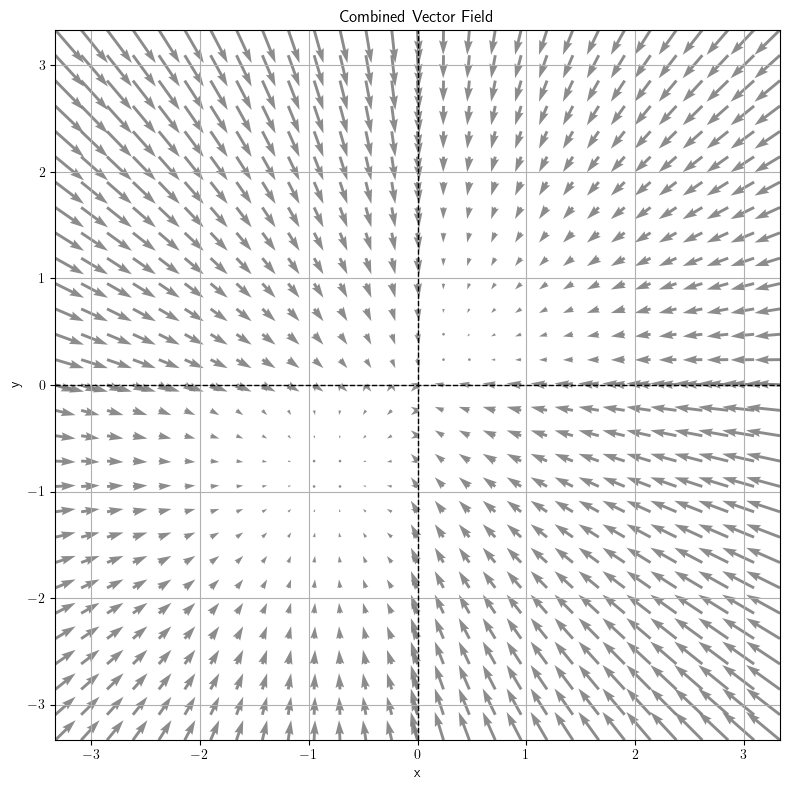

In [47]:
# Precompute Q-values
Q_GT = QvaluesGTvsGT(t, r, p, s, epsilon, d)[0]
Q_AD = QvaluesADvs00(t, r, p, s, epsilon, d)[0]

# Define vector field functions
def field1(x, y):
    u = alpha * (Q_GT[0] - Q_GT[1] - x)
    v = alpha * (Q_AD[0] - Q_AD[1] - y)
    return u, v

def field2(x, y):
    u = alpha * (Q_GT[0] - Q_GT[1] - x)
    v = alpha * (Q_GT[0] - Q_GT[1] - y)
    return u, v

def field3(x, y):
    u = alpha * (Q_AD[0] - Q_AD[1] - x)
    v = alpha * (Q_AD[0] - Q_AD[1] - y)
    return u, v

def field4(x, y):
    u = alpha * (Q_AD[0] - Q_AD[1] - x)
    v = alpha * (Q_GT[0] - Q_GT[1] - y)
    return u, v

# Helper to draw a vector field over a region
def add_vector_field(ax, field_func, x_range, y_range, density=15):
    x_vals = np.linspace(*x_range, density)
    y_vals = np.linspace(*y_range, density)
    X, Y = np.meshgrid(x_vals, y_vals)
    U, V = field_func(X, Y)
    ax.quiver(X, Y, U, V, angles='xy', scale_units='xy', scale=4, facecolor='grey', alpha=0.9)

# Create single combined plot
fig, ax = plt.subplots(figsize=(8, 8))

# Add all vector fields to the same axes
add_vector_field(ax, field1, (0, bound), (-bound, 0))
add_vector_field(ax, field2, (-bound, 0), (-bound, 0))
add_vector_field(ax, field3, (0, bound), (0, bound))
add_vector_field(ax, field4, (-bound, 0), (0, bound))

# Add formatting
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.set_xlim(-bound, bound)
ax.set_ylim(-bound, bound)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Combined Vector Field')
ax.grid(True)

plt.tight_layout()
plt.show()


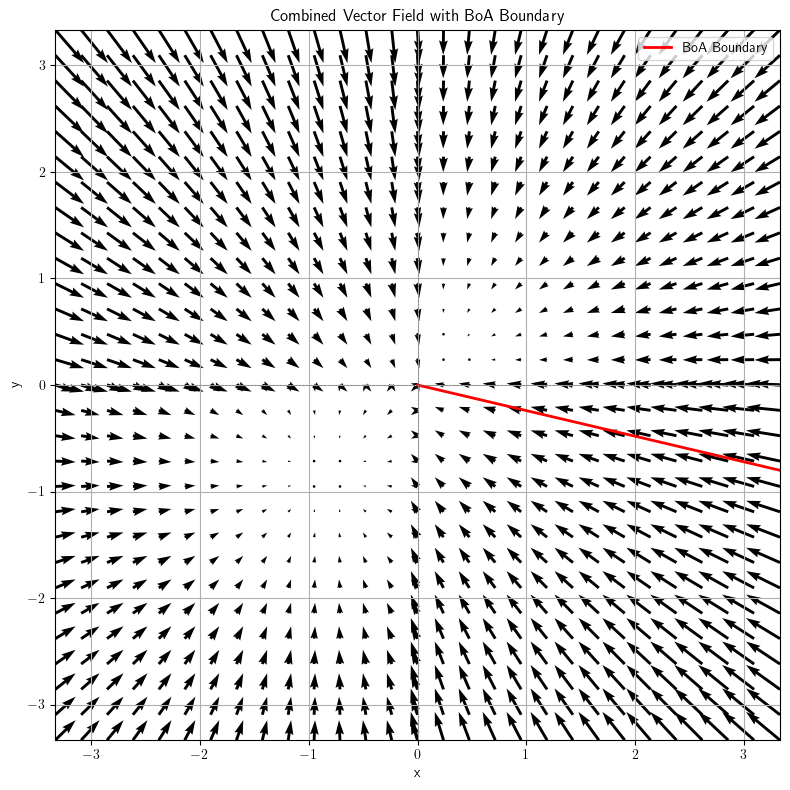

In [48]:


# Get Q-values
Q_GT = QvaluesGTvsGT(t, r, p, s, epsilon, d)[0]
Q_AD = QvaluesADvs00(t, r, p, s, epsilon, d)[0]

# Delta values
dx = Q_GT[0] - Q_GT[1]
dy = Q_AD[0] - Q_AD[1]

# Safe scaling
eps = 1e-8
inv_scale_dx = 1 / ((1 - d) * abs(dx) + eps)
inv_scale_dy = 1 / ((1 - d) * abs(dy) + eps)
a = min(inv_scale_dx, inv_scale_dy)

# Boundary endpoint
end_x = -a * dx
end_y = -a * dy

# Vector field functions
def field1(x, y): return alpha * (dx - x), alpha * (dy - y)
def field2(x, y): return alpha * (dx - x), alpha * (dx - y)
def field3(x, y): return alpha * (dy - x), alpha * (dy - y)
def field4(x, y): return alpha * (dy - x), alpha * (dx - y)

# Helper function to add a quiver field to an axis
def add_vector_field(ax, field_func, x_range, y_range, density=15):
    x_vals = np.linspace(*x_range, density)
    y_vals = np.linspace(*y_range, density)
    X, Y = np.meshgrid(x_vals, y_vals)
    U, V = field_func(X, Y)
    ax.quiver(X, Y, U, V, angles='xy', scale_units='xy', scale=4)

# Unified plot
fig, ax = plt.subplots(figsize=(8, 8))

# Add vector fields in four quadrants
add_vector_field(ax, field1, (0, bound), (-bound, 0))
add_vector_field(ax, field2, (-bound, 0), (-bound, 0))
add_vector_field(ax, field3, (0, bound), (0, bound))
add_vector_field(ax, field4, (-bound, 0), (0, bound))

# Add BoA boundary line
ax.plot([0, end_x], [0, end_y], color='red', linewidth=2, label='BoA Boundary')

# Axes, range, and labels
ax.axhline(0, color='gray', linestyle='--', linewidth=0.5)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.5)
ax.set_xlim(-bound, bound)
ax.set_ylim(-bound, bound)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Combined Vector Field with BoA Boundary')
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()


In [49]:
# Deltas
dx = Q_GT[0] - Q_GT[1]
dy = Q_AD[0] - Q_AD[1]

# Safe inverse scales
eps = 1e-8
inv_scale_dx = 1 / ((1 - d) * abs(dx) + eps)
inv_scale_dy = 1 / ((1 - d) * abs(dy) + eps)
a = min(inv_scale_dx, inv_scale_dy)

# Final result
result = 0.5 * a**2 * abs(dx) * abs(dy) * (1 - d)**2

print("Result:", result)

Result: 0.12015780959998383
